# Heart Disease UCI - Exploratory Data Analysis

Dataset: UCI Heart Disease (Cleveland subset, 303 patients, 13 predictors). Target: presence of heart disease (binary). Run `python scripts/download_data.py` first to fetch the raw file.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src import data

sns.set_theme(style='whitegrid', palette='deep')
FIG = Path.cwd().parent / 'report' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=150)
    plt.show()

## 1. Raw data and data quality

In [2]:
raw = data.load_raw()
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
print('Missing values per column (raw):')
raw.isna().sum()[lambda s: s > 0]

Missing values per column (raw):


ca      4
thal    2
dtype: int64

Only `ca` (4 rows) and `thal` (2 rows) have missing values. Both are categorical, so they are imputed with the mode. The original label `num` (0-4) is binarised: `0 -> no disease`, `1-4 -> disease`.

In [4]:
df = data.prepare()
print(df.shape, '| missing after cleaning:', int(df.isna().sum().sum()))
df.describe().T

(303, 14) | missing after cleaning: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 2. Class balance

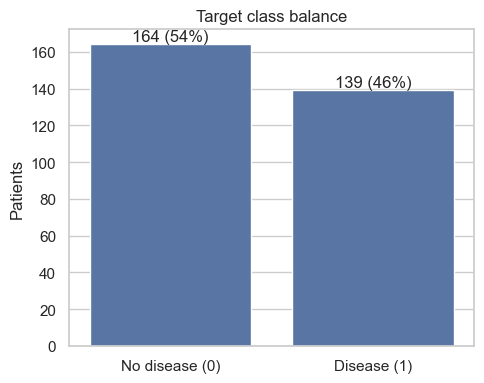

In [5]:
counts = df['target'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=['No disease (0)', 'Disease (1)'], y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, f'{v} ({v / len(df):.0%})', ha='center')
ax.set_ylabel('Patients'); ax.set_title('Target class balance')
save('class_balance')

The classes are close to balanced (~54% / 46%), so accuracy is meaningful and no resampling is needed. Recall and ROC-AUC are still reported because missing a sick patient is the costly error.

## 3. Numeric features

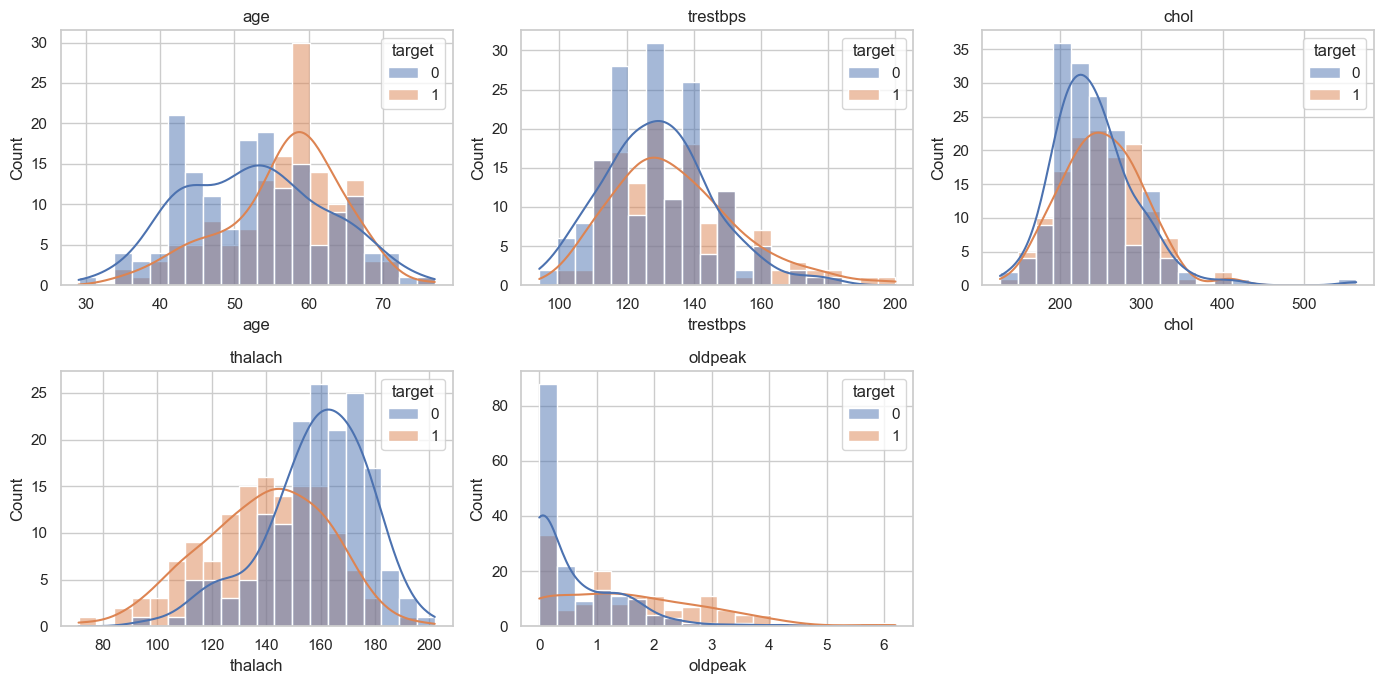

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), data.NUMERIC_FEATURES):
    sns.histplot(data=df, x=col, hue='target', kde=True, bins=20, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis('off')
save('numeric_histograms')

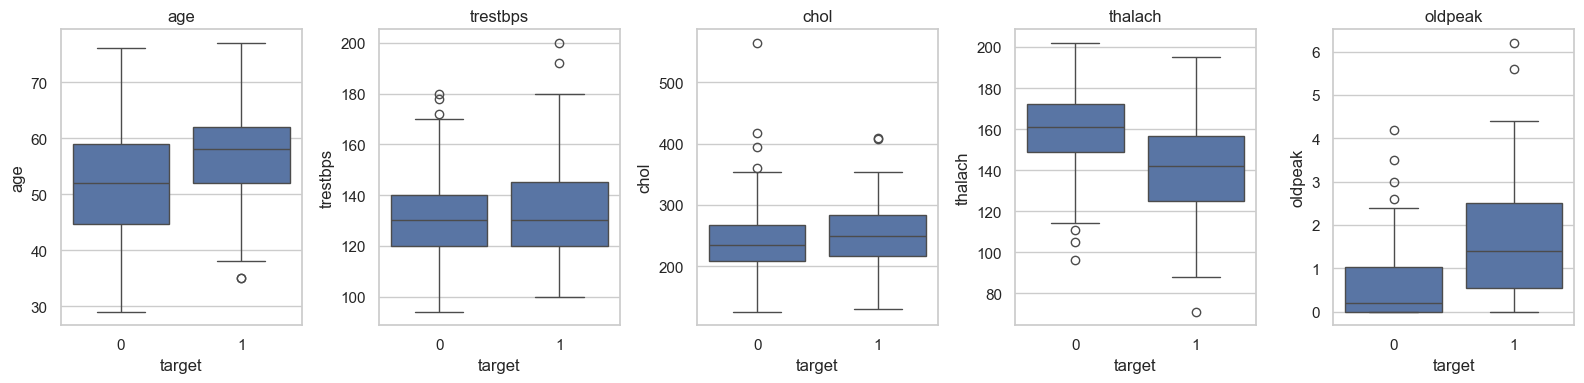

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, data.NUMERIC_FEATURES):
    sns.boxplot(data=df, x='target', y=col, ax=ax)
    ax.set_title(col)
save('numeric_boxplots')

## 4. Categorical features vs target

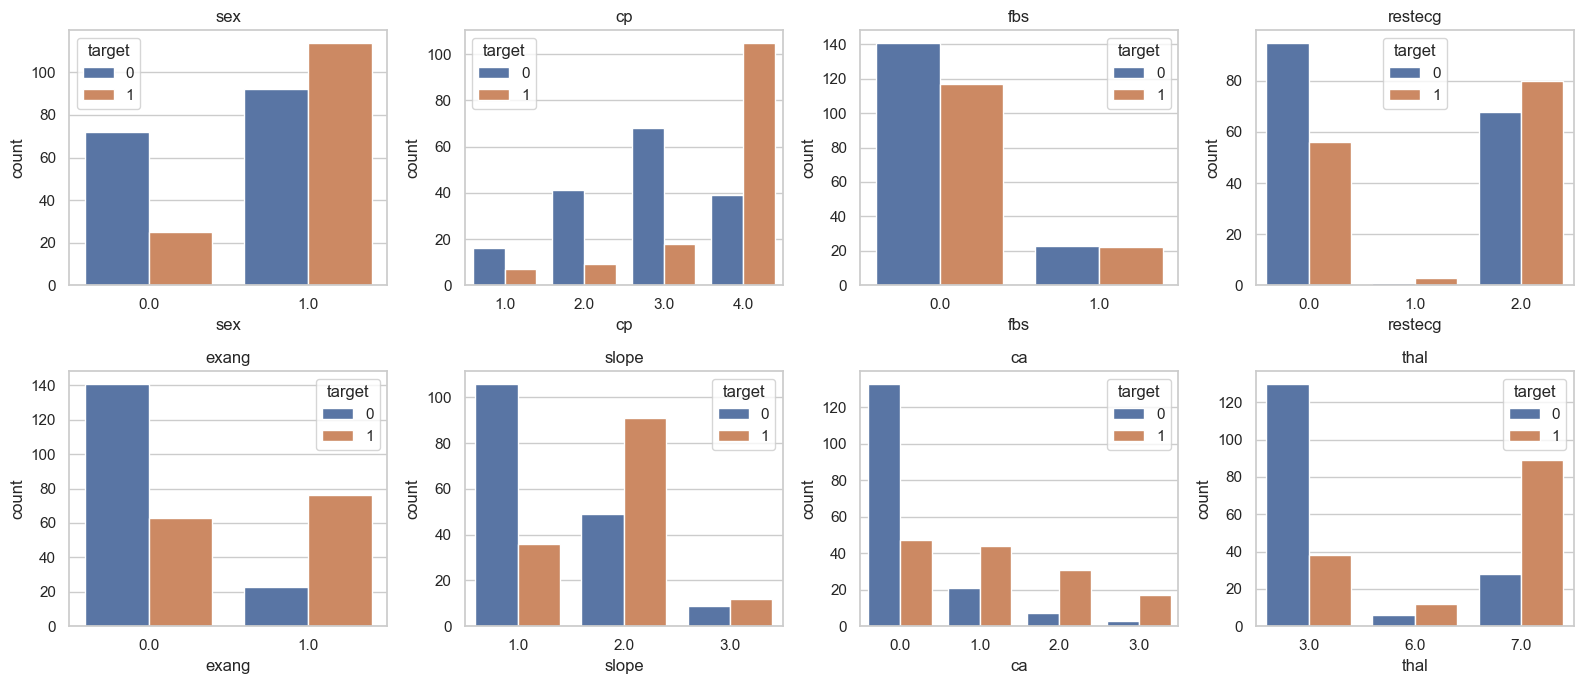

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), data.CATEGORICAL_FEATURES):
    sns.countplot(data=df, x=col, hue='target', ax=ax)
    ax.set_title(col)
save('categorical_counts')

## 5. Correlation analysis

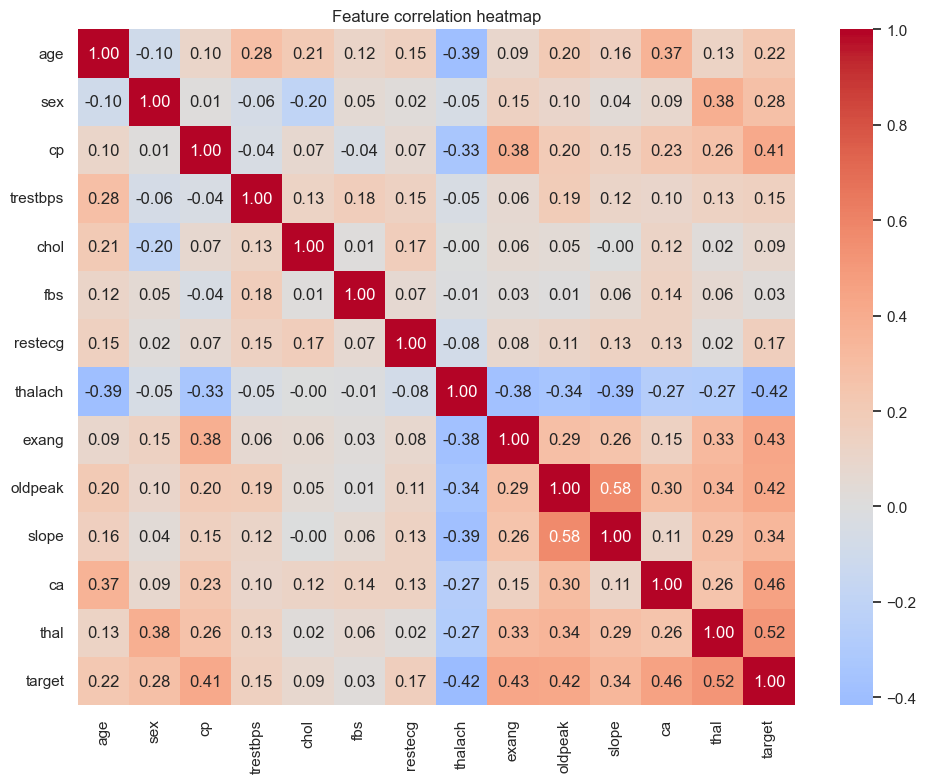

In [9]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Feature correlation heatmap')
save('correlation_heatmap')

In [10]:
corr['target'].drop('target').sort_values(key=abs, ascending=False).to_frame('corr_with_target')

,corr_with_target
thal,0.522057
ca,0.460033
exang,0.431894
oldpeak,0.424510
thalach,-0.417167
cp,0.414446
slope,0.339213
sex,0.276816
age,0.223120
restecg,0.169202


## Findings

- Data is small (303 rows) and clean after imputing 6 missing categorical values.
- Balanced target, so stratified CV is enough.
- Strongest linear correlations with the target: `thal` (0.52), `ca` (0.46), `exang` (0.43), `oldpeak` (0.42), `thalach` (-0.42, higher max heart rate = lower risk) and `cp` (0.41). `fbs` (0.03) and `chol` (0.09) are nearly uninformative on their own.
- `oldpeak` and `slope` are correlated with each other (0.58), a mild collinearity that matters for Logistic Regression coefficients but not for tree models.
- Numeric features are on different scales, so scaling is needed for Logistic Regression; categorical codes (`cp`, `thal`, `slope`...) are nominal/ordinal labels and are one-hot encoded.
- No extreme outliers need removing; tree models are robust to the mild ones in `chol` and `oldpeak`.